# Fase 6 · Figuras y resumen de entrega
**Responsabilidad:** figuras para el informe y el video, y `resumen.json` con los conteos de control.
El dashboard nativo se entrega por separado en Tableau.

| | |
|---|---|
| **Entrada** | salida de la fase 3 |
| **Salida** | `resultados/figuras/01…05_*.png` y `resultados/resumen.json` |

## 1. Carga y estilo

In [1]:
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from bi_airbnb import (ARCHIVO_ANALITICO, DIR_RESULTADOS, FORMATO_MIL, GOLD, MIN_N, NAVY, SEED,
                       TEAL, anfitriones_unicos, aplicar_estilo, cargar_base, descriptivos,
                       filtrar_min_n, guardar_figura)

todo, d, hosts = cargar_base()
aplicar_estilo()
d1 = filtrar_min_n(d, "localidad")   # localidades con n >= 30 (base de H1)

## 2. Precio mediano por localidad

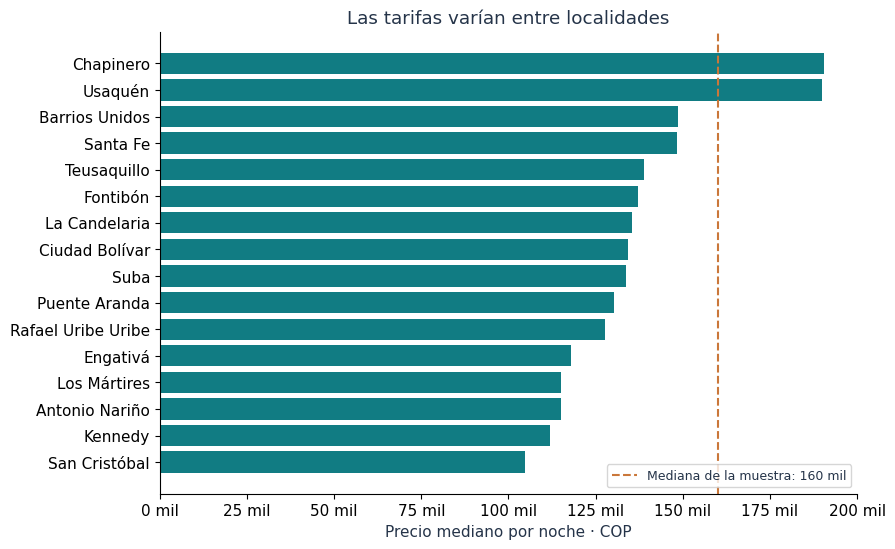

In [2]:
desc = descriptivos(d1, "localidad").sort_values("mediana")
mediana_muestra = d.precio_cop.median()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(desc.localidad, desc.mediana, color=TEAL)
ax.set(xlabel="Precio mediano por noche · COP", title="Las tarifas varían entre localidades")
ax.xaxis.set_major_formatter(FORMATO_MIL)
ax.axvline(mediana_muestra, color=GOLD, ls="--", label=f"Mediana de la muestra: {mediana_muestra/1000:.0f} mil")
ax.legend(loc="lower right", fontsize=9)
guardar_figura(fig, "01_localidades.png")

## 3. Distribución del precio

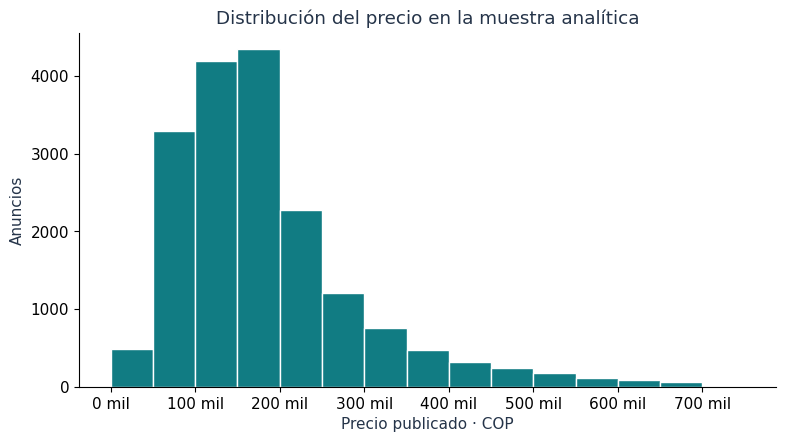

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(d.precio_cop, bins=np.arange(0, 750001, 50000), color=TEAL, edgecolor="white")
ax.set(xlabel="Precio publicado · COP", ylabel="Anuncios", title="Distribución del precio en la muestra analítica")
ax.xaxis.set_major_formatter(FORMATO_MIL)
guardar_figura(fig, "02_distribucion.png")

## 4. Capacidad y precio

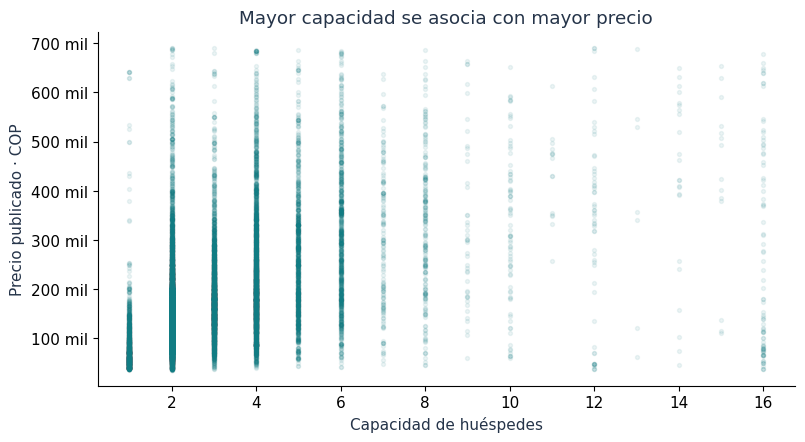

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(d.capacidad, d.precio_cop, s=8, alpha=.08, color=TEAL, rasterized=True)
ax.set(xlabel="Capacidad de huéspedes", ylabel="Precio publicado · COP", title="Mayor capacidad se asocia con mayor precio")
ax.yaxis.set_major_formatter(FORMATO_MIL)
guardar_figura(fig, "03_capacidad.png")

## 5. Mapa de calor localidad × tipo
Se vacían las celdas con menos de 30 anuncios.

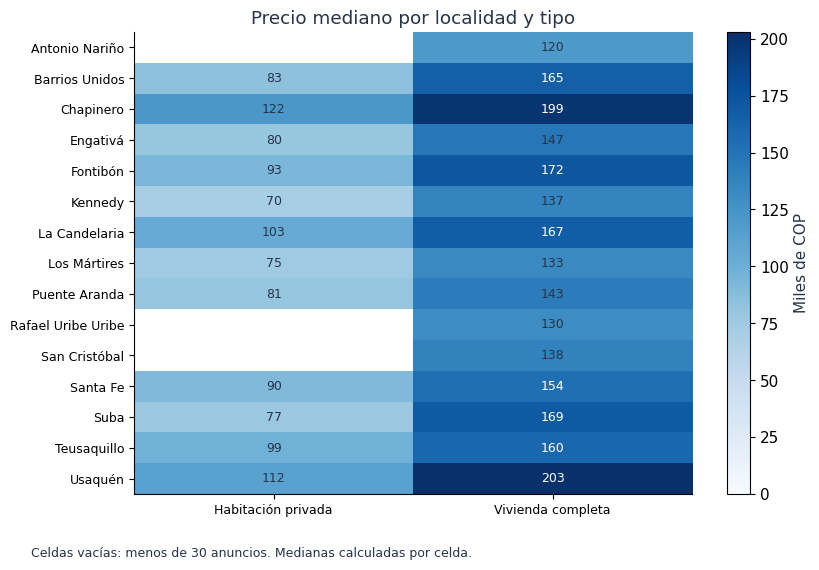

In [5]:
matriz = d.groupby(["localidad", "tipo_alojamiento"]).precio_cop.agg(["median", "count"]).reset_index()
matriz.loc[matriz["count"] < MIN_N, "median"] = np.nan
matriz = (matriz.pivot(index="localidad", columns="tipo_alojamiento", values="median")
          .dropna(how="all").dropna(axis=1, how="all"))
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(matriz / 1000, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(matriz.columns)), matriz.columns, fontsize=9)
ax.set_yticks(range(len(matriz)), matriz.index, fontsize=9)
for i in range(len(matriz)):
    for j in range(len(matriz.columns)):
        v = matriz.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v/1000:.0f}", ha="center", va="center",
                    color="white" if v > 150000 else NAVY, fontsize=9)
ax.set_title("Precio mediano por localidad y tipo")
fig.colorbar(im, ax=ax, label="Miles de COP")
fig.text(.01, .005, f"Celdas vacías: menos de {MIN_N} anuncios. Medianas calculadas por celda.", fontsize=9)
guardar_figura(fig, "04_mapa_calor.png")

## 6. Composición de la oferta

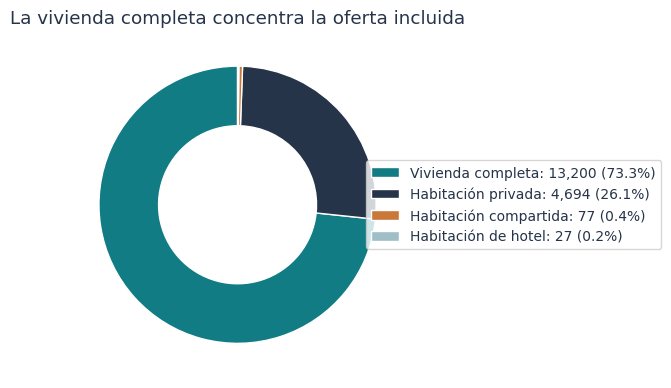

In [6]:
conteo = d.tipo_alojamiento.value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
sectores, _ = ax.pie(conteo, colors=[TEAL, NAVY, GOLD, "#9DBFC5"], startangle=90,
                  wedgeprops={"width": .43, "edgecolor": "white"})
ax.legend(sectores, [f"{nombre}: {n:,} ({n/len(d):.1%})" for nombre, n in conteo.items()],
          loc="center left", bbox_to_anchor=(.85, .5), fontsize=10)
ax.set_title("La vivienda completa concentra la oferta incluida")
guardar_figura(fig, "05_composicion.png")

## 7. `resumen.json`
Conteos de control, supuesto de homogeneidad de varianzas (Levene sobre `log(precio)` por localidad), hash de la entrada y una verificación cruzada con el filtro de Chapinero del dashboard.

In [7]:
levene = stats.levene(*[g.precio_log for _, g in d1.groupby("localidad")], center="median")
chapinero = d[d.localidad.eq("Chapinero")]
calificados = int(d.calificacion.notna().sum())

resumen = {
    "anuncios_originales": len(todo), "anuncios_analizados": len(d),
    "anfitriones_analizados": len(hosts), "calificaciones_validas": calificados,
    "calificaciones_faltantes": int(len(d) - calificados),
    "anuncios_activos_12m": int(d.resenas_12m.gt(0).sum()),
    "hosts_varios": int(anfitriones_unicos(d).n_anuncios.ge(2).sum()),
    "fecha_captura": str(d.fecha_captura.iloc[0]), "semilla_sensibilidad": SEED,
    "sha256_entrada": hashlib.sha256(ARCHIVO_ANALITICO.read_bytes()).hexdigest(),
    "levene_log_precio": {"W": float(levene.statistic), "p": float(levene.pvalue)},
    "control_filtro_chapinero": {"n": len(chapinero),
                                 "precio_mediano": float(chapinero.precio_cop.median()),
                                 "calificacion_promedio": float(chapinero.calificacion.mean())},
}
(DIR_RESULTADOS / "resumen.json").write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
resumen

{'anuncios_originales': 19505,
 'anuncios_analizados': 17998,
 'anfitriones_analizados': 7795,
 'calificaciones_validas': 14549,
 'calificaciones_faltantes': 3449,
 'anuncios_activos_12m': 12091,
 'hosts_varios': 2378,
 'fecha_captura': '2026-09-16',
 'semilla_sensibilidad': 20261018,
 'sha256_entrada': 'ebbfa623a429c6baf4dd11fafbaab12d38d2ae8c2b723638225b44e7c9c040bf',
 'levene_log_precio': {'W': 14.761960059532896, 'p': 1.657539918276452e-38},
 'control_filtro_chapinero': {'n': 4675,
  'precio_mediano': 190531.0,
  'calificacion_promedio': 4.692919909615868}}